In [148]:
# Выполнил: Осипов Никита Андреевич

In [149]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

In [150]:
# Данные и анализ графика

In [151]:
url_wti = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=WTISPLC'
url_ind = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=INDPRO'
url_dol = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTWEXBGS'

In [152]:
df = pd.read_csv(url_wti)
indpro = pd.read_csv(url_ind)
dollar = pd.read_csv(url_dol)

In [153]:
print(df)
print(indpro)
print(dollar)

    observation_date  WTISPLC
0         1946-01-01     1.17
1         1946-02-01     1.17
2         1946-03-01     1.17
3         1946-04-01     1.27
4         1946-05-01     1.27
..               ...      ...
963       2026-04-01   100.32
964       2026-05-01   102.13
965       2026-06-01    84.81
966       2026-07-01    80.46
967       2026-08-01    83.90

[968 rows x 2 columns]
     observation_date    INDPRO
0          1919-01-01    4.8739
1          1919-02-01    4.6585
2          1919-03-01    4.5238
3          1919-04-01    4.6046
4          1919-05-01    4.6315
...               ...       ...
1287       2026-04-01  102.5783
1288       2026-05-01  102.6396
1289       2026-06-01  102.8420
1290       2026-07-01  103.0454
1291       2026-08-01  103.0682

[1292 rows x 2 columns]
     observation_date  DTWEXBGS
0          2006-01-02  101.4155
1          2006-01-03  100.7558
2          2006-01-04  100.2288
3          2006-01-05  100.2992
4          2006-01-06  100.0241
...            

In [154]:
df.columns = ['date', 'wti']
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')
df['wti'] = pd.to_numeric(df['wti'], errors='coerce')

In [155]:
indpro.columns = ['date', 'indpro']
indpro['date'] = pd.to_datetime(indpro['date'])
indpro = indpro.set_index('date')['indpro']
indpro = pd.to_numeric(indpro, errors='coerce')

In [156]:
dollar.columns = ['date', 'dollar']
dollar['date'] = pd.to_datetime(dollar['date'])
dollar = dollar.set_index('date')['dollar']
dollar = pd.to_numeric(dollar, errors='coerce').resample('MS').mean()

In [157]:
df['indpro'] = indpro
df['dollar'] = dollar

In [158]:
df = df.loc['2010-01-01':'2026-08-01'].dropna()

In [159]:
df['winter'] = (df.index.month.isin([11, 12, 1, 2, 3])).astype(int)

In [160]:
df.shape

(200, 4)

In [161]:
df.head()

,wti,indpro,dollar,winter
date,,,,
2010-01-01,78.22,89.3426,92.440300,1
2010-02-01,76.42,89.6779,93.886680,1
2010-03-01,81.24,90.2928,93.149878,1
2010-04-01,84.48,90.5991,92.639086,0
2010-05-01,73.84,91.8230,95.530640,0


In [162]:
df.tail()

,wti,indpro,dollar,winter
date,,,,
2026-04-01,100.32,102.5783,119.036318,0
2026-05-01,102.13,102.6396,118.779185,0
2026-06-01,84.81,102.8420,120.083448,0
2026-07-01,80.46,103.0454,120.597045,0
2026-08-01,83.90,103.0682,118.851229,0


In [163]:
df.describe()

,wti,indpro,dollar,winter
count,200.000000,200.000000,200.000000,200.000000
mean,72.108900,99.409148,109.238908,0.415000
std,20.675769,3.374730,12.013478,0.493958
min,16.550000,84.561900,86.317805,0.000000
25%,56.217500,98.364200,94.451223,0.000000
50%,71.805000,100.276250,113.199981,0.000000
75%,88.447500,101.431075,119.233644,1.000000
max,114.840000,104.100400,128.836952,1.000000


In [164]:
df.isna().sum()

wti       0
indpro    0
dollar    0
winter    0
dtype: int64

__Вывод:__ \
После среза и dropna имею следующие результаты. Всего 200 строк, 4 столбца. Начало начинается с 2010-01-01, конец 2026-08-01. Пропусков нет. По цене, среднее 72.7 USD, минимум 16.55, максимум 114.84.

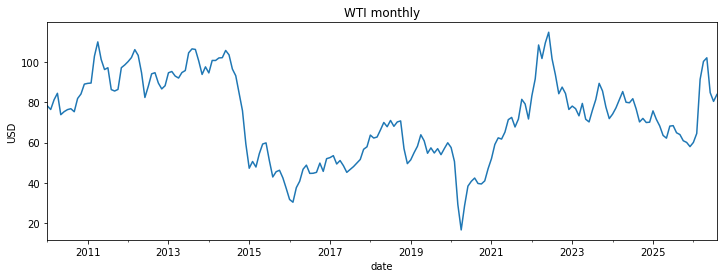

In [165]:
y = df['wti']
y.plot(figsize=(12, 4))
plt.ylabel('USD')
plt.title('WTI monthly')
plt.show()

__Вывод:__ \
Уровень не держится. Спад в 2014–2016, обвал 2020, скачок 2022. Повторяющейся годовой волны нет.

In [166]:
train = y.iloc[:-10]
test = y.iloc[-10:]
print('train', train.shape, train.index.min(), train.index.max())
print('test', test.shape, test.index.min(), test.index.max())
print(train.tail())
print(test)

train (190,) 2010-01-01 00:00:00 2025-10-01 00:00:00
test (10,) 2025-11-01 00:00:00 2026-08-01 00:00:00
date
2025-06-01    68.17
2025-07-01    68.39
2025-08-01    64.86
2025-09-01    63.96
2025-10-01    60.89
Name: wti, dtype: float64
date
2025-11-01     60.06
2025-12-01     57.97
2026-01-01     60.04
2026-02-01     64.51
2026-03-01     91.38
2026-04-01    100.32
2026-05-01    102.13
2026-06-01     84.81
2026-07-01     80.46
2026-08-01     83.90
Name: wti, dtype: float64


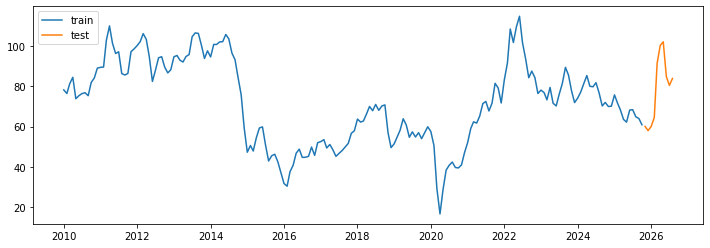

In [167]:
plt.figure(figsize=(12, 4))
plt.plot(train, label='train')
plt.plot(test, label='test')
plt.legend()
plt.show()

__Вывод:__ \
В train заложено 190 месяцев, с 2010-01 по 2025-10, последняя цена 60.89. В test заложено 10 месяцев, с 2025-11 по 2026-08, от 57.97 до 102.13.

In [168]:
# Стационарность уровня

In [169]:
print('ADF p_value', adfuller(train)[1])

ADF p_value 0.222562303644035


In [170]:
print('KPSS p_value', kpss(train)[1])

KPSS p_value 0.1


__Вывод:__ \
ADF p = 0.22 > 0.05 не стационарен. KPSS p = 0.1, стационарен. Тесты спорят, уровень нестационарный.

In [171]:
# Разность

In [172]:
y_d1 = train.diff().dropna()
print(y_d1.shape)

(189,)


In [173]:
print('ADF p_value', adfuller(y_d1)[1])

ADF p_value 2.3562228502057493e-16


In [174]:
print('KPSS p_value', kpss(y_d1)[1])

KPSS p_value 0.1


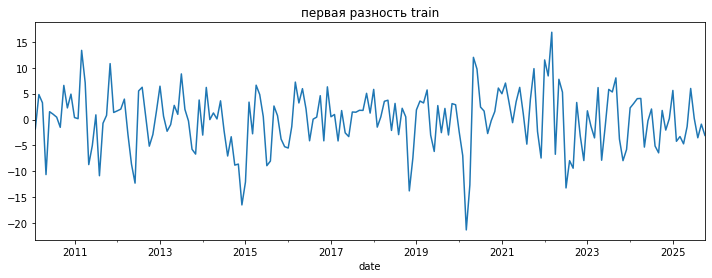

In [175]:
y_d1.plot(figsize=(12, 4))
plt.title('первая разность train')
plt.show()

__Вывод:__ \
Всего 189 точек, колеблется около нуля. ADF p = 2.4e-16 < 0.05, корень отвергнут. KPSS p ≥ 0.1 > 0.05, стационарность не отвергнута. Ряд стационарен, d = 1.

In [176]:
# Автокорреляция разности

In [177]:
print(acorr_ljungbox(y_d1, return_df=True, lags=[6, 12, 24]))

      lb_stat  lb_pvalue
6   16.933497   0.009531
12  18.177361   0.110410
24  39.743397   0.022783


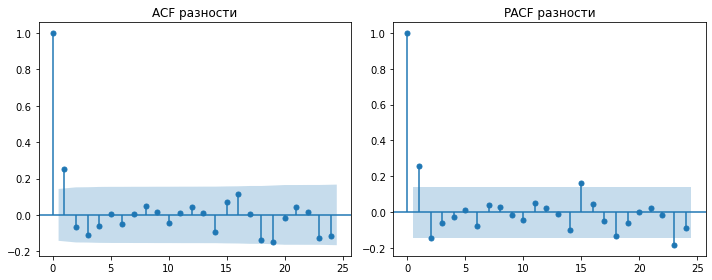

In [178]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_acf(y_d1, ax=ax[0], lags=24)
plot_pacf(y_d1, ax=ax[1], lags=24)
ax[0].set_title('ACF разности')
ax[1].set_title('PACF разности')
plt.tight_layout()
plt.show()

__Вывод:__ \
Ljung-Box при лаг 6 p_value = 0.0095, лаг 12 p_value = 0.11, лаг 24 p_value = 0.023. Автокорреляция есть. На ACF значим лаг 1, дальше столбики в коридоре. Подходящий порядок является MA(1).

In [179]:
# ARMA

In [180]:
print('AR(1)', ARIMA(y_d1, order=(1, 0, 0)).fit().aic)
print('AR(2)', ARIMA(y_d1, order=(2, 0, 0)).fit().aic)
print('MA(1)', ARIMA(y_d1, order=(0, 0, 1)).fit().aic)
print('ARMA(1,1)', ARIMA(y_d1, order=(1, 0, 1)).fit().aic)

AR(1) 1187.7296219490831
AR(2) 1185.8521557977697
MA(1) 1185.2403880007605
ARMA(1,1) 1187.158106340198


__Вывод:__ \
AIC: AR(1) 1187.73, AR(2) 1185.85, MA(1) 1185.24, ARMA(1,1) 1187.16. Минимум у MA(1).

In [181]:
arma = ARIMA(y_d1, order=(0, 0, 1)).fit()
print(arma.summary())

                               SARIMAX Results                                
Dep. Variable:                    wti   No. Observations:                  189
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -589.620
Date:                Mon, 05 Oct 2026   AIC                           1185.240
Time:                        15:02:58   BIC                           1194.966
Sample:                    02-01-2010   HQIC                          1189.180
                         - 10-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.1004      0.536     -0.187      0.851      -1.150       0.949
ma.L1          0.2944      0.070      4.220      0.000       0.158       0.431
sigma2        29.9945      2.664     11.259      0.0

In [182]:
print(acorr_ljungbox(arma.resid.dropna(), return_df=True, lags=[6, 12]))

     lb_stat  lb_pvalue
6   3.194391   0.784083
12  4.378515   0.975598


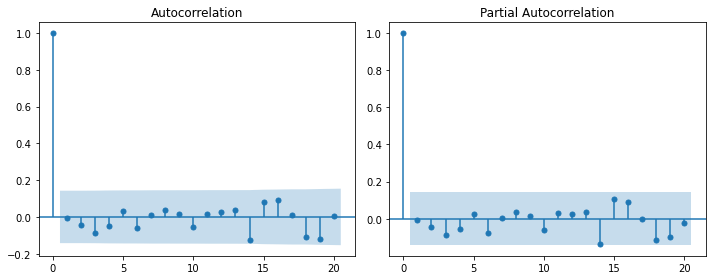

In [183]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_acf(arma.resid.dropna(), ax=ax[0], lags=20)
plot_pacf(arma.resid.dropna(), ax=ax[1], lags=20)
plt.tight_layout()
plt.show()

In [184]:
pred_d = arma.predict()
fc_d = arma.forecast(steps=10)
arma_oos = train.iloc[-1] + np.cumsum(fc_d.values)

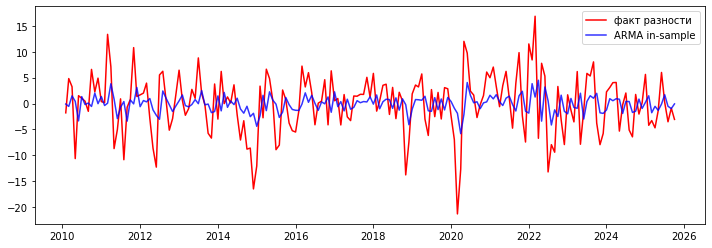

In [185]:
plt.figure(figsize=(12, 4))
plt.plot(y_d1, color='red', label='факт разности')
plt.plot(pred_d, color='blue', alpha=0.8, label='ARMA in-sample')
plt.legend()
plt.show()

In [186]:
print('MAE in-sample ARMA', np.mean(np.abs(y_d1 - pred_d)))
print(arma_oos)

MAE in-sample ARMA 4.288394806925847
[59.90813093 59.80774095 59.70735098 59.60696101 59.50657103 59.40618106
 59.30579109 59.20540111 59.10501114 59.00462116]


__Вывод:__ \
ma.L1 = 0.294, p = 0. const = −0.10, p = 0.85, не значим. Ljung-Box p = 0.78 и 0.98, столбики ACF в коридоре. Прогноз уровня на test: 59.91, 59.81, …, 59.00.

In [187]:
# ARIMA

In [188]:
print('ARIMA(1,1,0)', ARIMA(train, order=(1, 1, 0)).fit().aic)
print('ARIMA(0,1,1)', ARIMA(train, order=(0, 1, 1)).fit().aic)
print('ARIMA(1,1,1)', ARIMA(train, order=(1, 1, 1)).fit().aic)

ARIMA(1,1,0) 1185.7645490076789
ARIMA(0,1,1) 1183.278482687601
ARIMA(1,1,1) 1185.197095370889


__Вывод:__ \
AIC: ARIMA(1,1,0) 1185.76, ARIMA(0,1,1) 1183.28, ARIMA(1,1,1) 1185.20. Минимум у (0,1,1).

In [189]:
res_arima = ARIMA(train, order=(0, 1, 1)).fit()
print(res_arima.summary())

                               SARIMAX Results                                
Dep. Variable:                    wti   No. Observations:                  190
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -589.639
Date:                Mon, 05 Oct 2026   AIC                           1183.278
Time:                        15:03:00   BIC                           1189.762
Sample:                    01-01-2010   HQIC                          1185.905
                         - 10-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.2945      0.068      4.358      0.000       0.162       0.427
sigma2        30.0005      2.638     11.374      0.000      24.831      35.170
Ljung-Box (L1) (Q):                   0.01   Jarque-

In [190]:
print(acorr_ljungbox(res_arima.resid.dropna(), return_df=True, lags=[6, 12]))

    lb_stat  lb_pvalue
6   2.75588   0.838803
12  3.88502   0.985423


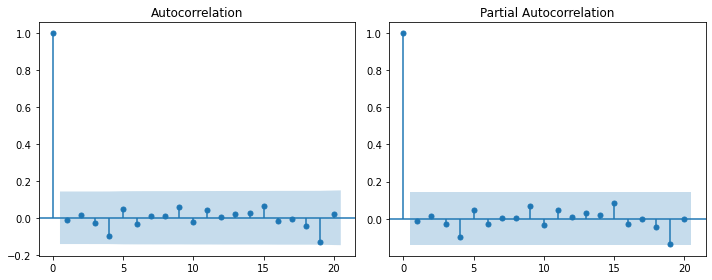

In [191]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_acf(res_arima.resid.dropna(), ax=ax[0], lags=20)
plot_pacf(res_arima.resid.dropna(), ax=ax[1], lags=20)
plt.tight_layout()
plt.show()

In [192]:
pred_arima = res_arima.predict()
fc_arima = res_arima.forecast(steps=10)

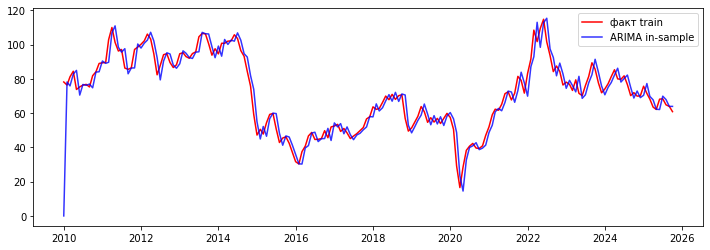

In [193]:
plt.figure(figsize=(12, 4))
plt.plot(train, color='red', label='факт train')
plt.plot(pred_arima, color='blue', alpha=0.8, label='ARIMA in-sample')
plt.legend()
plt.show()

In [194]:
print('MAE in-sample ARIMA', np.mean(np.abs(train.iloc[1:] - pred_arima.iloc[1:])))
print(fc_arima)

MAE in-sample ARIMA 4.285661005631351
2025-11-01    59.98542
2025-12-01    59.98542
2026-01-01    59.98542
2026-02-01    59.98542
2026-03-01    59.98542
2026-04-01    59.98542
2026-05-01    59.98542
2026-06-01    59.98542
2026-07-01    59.98542
2026-08-01    59.98542
Freq: MS, Name: predicted_mean, dtype: float64


__Вывод:__ \
ma.L1 = 0.295, p = 0. Ljung-Box p = 0.84 и 0.99. In-sample почти совпадает с фактом. Прогноз на 10 месяцев плоский, около 59.99.

In [195]:
# ARIMAX

In [196]:
ex_tr = df[['indpro', 'dollar', 'winter']].iloc[:-10]
ex_te = df[['indpro', 'dollar', 'winter']].iloc[-10:]
print(ex_tr.shape, ex_te.shape)
ex_te

(190, 3) (10, 3)


,indpro,dollar,winter
date,,,
2025-11-01,101.0344,121.417717,1
2025-12-01,101.4941,120.188323,1
2026-01-01,101.0388,119.229810,1
2026-02-01,101.9053,117.906021,1
2026-03-01,101.7336,119.919855,1
2026-04-01,102.5783,119.036318,0
2026-05-01,102.6396,118.779185,0
2026-06-01,102.8420,120.083448,0
2026-07-01,103.0454,120.597045,0


In [197]:
res_x = ARIMA(train, order=(0, 1, 1), exog=ex_tr).fit()
print(res_x.summary())

                               SARIMAX Results                                
Dep. Variable:                    wti   No. Observations:                  190
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -576.871
Date:                Mon, 05 Oct 2026   AIC                           1163.742
Time:                        15:03:03   BIC                           1179.951
Sample:                    01-01-2010   HQIC                          1170.308
                         - 10-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
indpro         0.7942      0.344      2.311      0.021       0.121       1.468
dollar        -1.1989      0.256     -4.684      0.000      -1.701      -0.697
winter        -1.0216      0.916     -1.115      0.2

In [198]:
print(acorr_ljungbox(res_x.resid.dropna(), return_df=True, lags=[6, 12]))

     lb_stat  lb_pvalue
6   0.995716   0.985774
12  1.459234   0.999887


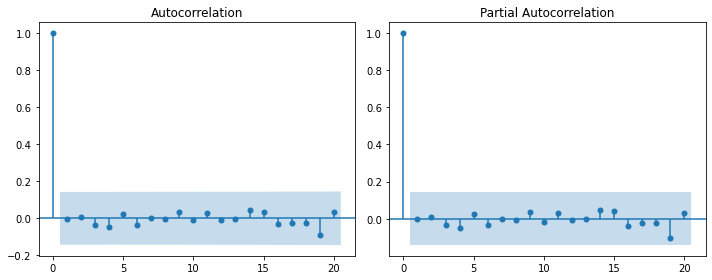

In [199]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_acf(res_x.resid.dropna(), ax=ax[0], lags=20)
plot_pacf(res_x.resid.dropna(), ax=ax[1], lags=20)
plt.tight_layout()
plt.show()

In [200]:
pred_x = res_x.predict()
fc_x = res_x.forecast(steps=10, exog=ex_te)

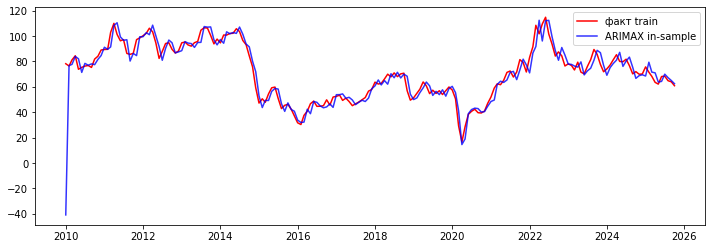

In [201]:
plt.figure(figsize=(12, 4))
plt.plot(train, color='red', label='факт train')
plt.plot(pred_x, color='blue', alpha=0.8, label='ARIMAX in-sample')
plt.legend()
plt.show()

In [202]:
print('MAE in-sample ARIMAX', np.mean(np.abs(train.iloc[1:] - pred_x.iloc[1:])))
print(fc_x)

MAE in-sample ARIMAX 3.9808769463695914
2025-11-01    58.557973
2025-12-01    60.397017
2026-01-01    61.184625
2026-02-01    63.459912
2026-03-01    60.909098
2026-04-01    63.660839
2026-05-01    64.017808
2026-06-01    62.614822
2026-07-01    62.160587
2026-08-01    64.271815
Freq: MS, Name: predicted_mean, dtype: float64


__Вывод:__ \
indpro = 0.79, p = 0.021. dollar = −1.20, p = 0. winter = −1.02, p = 0.265, не значим. AIC 1163.7 против 1183.3 у ARIMA. Ljung-Box p = 0.99 и 1.00. Прогноз на test от 58.6 до 64.3

In [203]:
# Сравнение с фактом

In [204]:
naive = pd.Series(train.iloc[-1], index=test.index)
cmp = pd.DataFrame({
    'fact': test,
    'naive': naive,
    'ARMA': arma_oos,
    'ARIMA': fc_arima.values,
    'ARIMAX': fc_x.values
}, index=test.index)
cmp

,fact,naive,ARMA,ARIMA,ARIMAX
date,,,,,
2025-11-01,60.06,60.89,59.908131,59.98542,58.557973
2025-12-01,57.97,60.89,59.807741,59.98542,60.397017
2026-01-01,60.04,60.89,59.707351,59.98542,61.184625
2026-02-01,64.51,60.89,59.606961,59.98542,63.459912
2026-03-01,91.38,60.89,59.506571,59.98542,60.909098
2026-04-01,100.32,60.89,59.406181,59.98542,63.660839
2026-05-01,102.13,60.89,59.305791,59.98542,64.017808
2026-06-01,84.81,60.89,59.205401,59.98542,62.614822
2026-07-01,80.46,60.89,59.105011,59.98542,62.160587


In [205]:
print('RMSE naive', np.sqrt(np.mean((cmp['fact'] - cmp['naive'])**2)))
print('RMSE ARMA', np.sqrt(np.mean((cmp['fact'] - cmp['ARMA'])**2)))
print('RMSE ARIMA', np.sqrt(np.mean((cmp['fact'] - cmp['ARIMA'])**2)))
print('RMSE ARIMAX', np.sqrt(np.mean((cmp['fact'] - cmp['ARIMAX'])**2)))
print('MAE naive', np.mean(np.abs(cmp['fact'] - cmp['naive'])))
print('MAE ARMA', np.mean(np.abs(cmp['fact'] - cmp['ARMA'])))
print('MAE ARIMA', np.mean(np.abs(cmp['fact'] - cmp['ARIMA'])))
print('MAE ARIMAX', np.mean(np.abs(cmp['fact'] - cmp['ARIMAX'])))

RMSE naive 23.85949748003926
RMSE ARMA 25.065375814901596
RMSE ARIMA 24.536872722662626
RMSE ARIMAX 22.2446141237325
MAE naive 18.588
MAE ARMA 19.46917214494269
MAE ARIMA 18.97566398173103
MAE ARIMAX 17.148878871305648


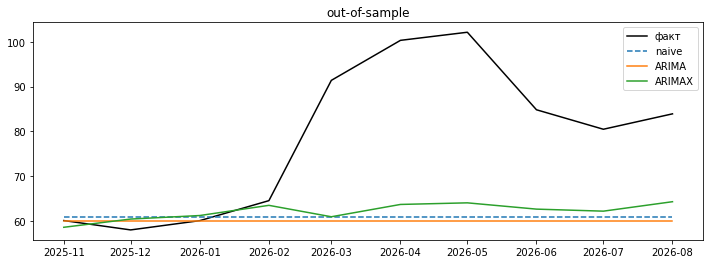

In [206]:
plt.figure(figsize=(12, 4))
plt.plot(test, color='black', label='факт')
plt.plot(cmp['naive'], ls='--', label='naive')
plt.plot(cmp['ARIMA'], label='ARIMA')
plt.plot(cmp['ARIMAX'], label='ARIMAX')
plt.legend()
plt.title('out-of-sample')
plt.show()

__Вывод:__ \
RMSE: naive 23.86, ARMA 25.07, ARIMA 24.54, ARIMAX 22.24. MAE: 18.59, 19.47, 18.98, 17.15. Минимум у ARIMAX(0,1,1). Факт с марта по май 2026 равен 91.38, 100.32 и 102.13, прогнозы всех моделей остаются в диапазоне 59–64.

__Итог__ \
Лучшей моделью явялется ARIMAX(0,1,1). На 10 месяцах вне обучения у неё RMSE 22.24 и MAE 17.15. У наивного прогноза 23.86 и 18.59, у ARMA на разности 25.07 и 19.47, у ARIMA(0,1,1) 24.54 и 18.98. \
Уровень нестационарен при ADF p_value = 0.22, график без постоянного среднего. После одной разности ADF p_value = 2.4e-16, KPSS p ≥ 0.1, ряд стационарен, поэтому d = 1. На разности ACF обрывается после лага 1, минимальный AIC у MA(1) равен 1185.24. На уровне тот же порядок даёт ARIMA(0,1,1), AIC 1183.28. \
indpro = 0.79, p = 0.021, dollar = −1.20, p = 0. Оба значимы, знаки соответствуют спросу на топливо и котировке нефти в долларах. winter = −1.02, p = 0.265, не значим. AIC с регрессорами 1163.7. Остатки всех трёх моделей без автокорреляции Ljung-Box p_value от 0.78 до 1.00. \
Чистая ARIMA наивный прогноз не бьёт. Выигрыш ARIMAX небольшой, в марте по май 2026 факт равен 91.38, 100.32 и 102.13, а прогнозы всех моделей остаются в диапазоне 59–64. Сдвиг даёт доллар и промпроизводство, скачок не пойман.